## Лабораторная работа №1 | Вариант 6

Выполнил: Сысуев Павел М8Щ-312БВ-24

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
eye3x3 = np.eye(3)
print(eye3x3)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [3]:
matrix5x5 = np.zeros((5, 5), dtype=int)
for i in (1, 2, 3, 4):
    matrix5x5[i, i - 1] = i

print(matrix5x5)

[[0 0 0 0 0]
 [1 0 0 0 0]
 [0 2 0 0 0]
 [0 0 3 0 0]
 [0 0 0 4 0]]


3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [4]:
# Первая print: 9
# Второй print: 10

4. Как найти самое часто встречаемое значение между двумя массивами? 

In [5]:
'''
1. Нужно объединить массивы в один
2. НУжно найти элемент с максимальным числом вхождений
'''

a = np.array([1, 2, 3, 4])
b = np.array([1, 1, 1, 2, 2, 2, 2, 2, 3, 4])

c = np.concatenate([a, b])
vals, counts = np.unique(c, return_counts = True)
print(vals[counts.argmax()])


2


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [6]:
settings = np.seterr(all = 'ignore')


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [7]:
import random

def generate(n):
    for _ in range(n):
        yield random.randint(1, 100)


7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [8]:
array10 = np.fromiter(generate(10), dtype=int, count = 10)
print(array10)

[19 66 81 50 72 45 12 69 27 83]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [9]:
array10x2 = np.fromiter(generate(20), dtype=int, count=20).reshape(10, 2)
print(f"Декартовые координаты: \n{array10x2}")

x, y = array10x2[:, 0], array10x2[:, 1]

r =  np.sqrt(x**2 + y**2)
phi = np.arctan2(y, x)

polar = np.column_stack((r, phi))
print(f"Полярные координаты: \n{polar}")


Декартовые координаты: 
[[82 91]
 [65 56]
 [66 44]
 [50 36]
 [95 73]
 [25 24]
 [38 60]
 [57 77]
 [48 35]
 [22 43]]
Полярные координаты: 
[[122.49489785   0.83737443]
 [ 85.79627032   0.71115471]
 [ 79.32212806   0.5880026 ]
 [ 61.6116872    0.62402305]
 [119.80818002   0.65518672]
 [ 34.6554469    0.76499283]
 [ 71.02112362   1.00622693]
 [ 95.8018789    0.93355818]
 [ 59.40538696   0.63003391]
 [ 48.3011387    1.09788972]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [10]:
pixel = np.dtype([
    ('position', [('x', float), ('y', float)]),
    ('color',    [('r', float), ('g', float), ('b', float)])
])

10. Как конвертировать тип массив от float32 в int32 in place?

In [11]:
Z = np.array([((0, 0), (255, 0, 0)),
              ((1, 2), (0, 255, 0))], dtype=pixel)

import pandas as pd
df = pd.DataFrame(Z)
print(df)

     position              color
0  (0.0, 0.0)  (255.0, 0.0, 0.0)
1  (1.0, 2.0)  (0.0, 255.0, 0.0)


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [12]:
import pandas as pd

In [13]:
# Load dataset here
data = pd.read_csv("./student_perfomance.csv")
print(data.shape)

(6607, 20)


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [14]:
print(data["Sleep_Hours"].mean())

7.029060087785682


2. Сколько процентов студентов посещают внеклассовые активности?

In [15]:
count_yes = data["Extracurricular_Activities"].value_counts().get("Yes", 0)
count = len(data["Extracurricular_Activities"])
print(count_yes / count * 100)

59.60345088542455


3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [16]:
x = data.groupby("Gender")["Exam_Score"].mean()
if x.get("Male", 0) > x.get("Female", 0):
    print("МУжчины в среднем сдали экзамен лучше")
else:
    print("Женщины в среднем сдали экзамен лучше")

# Женщины сдают экзамен лучше в среднем, чем мужчины.


Женщины в среднем сдали экзамен лучше


4. Выведите 25 и 75 перцентили времени сна студентов

In [17]:
q25 = data["Sleep_Hours"].quantile(0.25)
q75 = data["Sleep_Hours"].quantile(0.75)

print(f"25-й перцентиль: {q25}")
print(f"75-й перцентиль: {q75}")

25-й перцентиль: 6.0
75-й перцентиль: 8.0


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [18]:
data25 = data[data["Sleep_Hours"] <= q25]
data75 = data[data["Sleep_Hours"] >= q75]
exam_score_25 = data25["Exam_Score"].mean()
exam_score_75 = data75["Exam_Score"].mean()
print(f"Средний балл за экзамен для студентов, которые спят меньше 25%: {exam_score_25}")
print(f"Средний балл за экзамен для студентов, которые спят больше 75%: {exam_score_75}")   

# Ответ: нет, не правда

Средний балл за экзамен для студентов, которые спят меньше 25%: 67.28109243697479
Средний балл за экзамен для студентов, которые спят больше 75%: 67.18704746580853


6. Влияет ли физическая активность на результаты экзамена?

In [19]:
data.groupby("Physical_Activity")["Exam_Score"].mean()

# Практически не меняет на результат экзамена

Physical_Activity
0    67.521739
1    66.969121
2    67.185003
3    67.196071
4    67.313016
5    67.603878
6    68.093750
Name: Exam_Score, dtype: float64

7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [20]:
high_edu = data[data["Parental_Education_Level"].isin(["College", "Postgraduate"])]
other_edu = data[~data["Parental_Education_Level"].isin(["College", "Postgraduate"])]

print(f"Средний балл за экзамен для студентов, родители которых имеют высшее образование: {high_edu['Exam_Score'].mean()}")
print(f"Средний балл за экзамен для студентов, родители которых не имеют высшего образования: {other_edu['Exam_Score'].mean()}")

Средний балл за экзамен для студентов, родители которых имеют высшее образование: 67.57528840315726
Средний балл за экзамен для студентов, родители которых не имеют высшего образования: 66.89797766374886


8. Как влияет участие родителей на результаты экзаменов

In [27]:
print(data.groupby("Parental_Involvement")["Exam_Score"].mean().sort_values(ascending=False))

Parental_Involvement
High      68.092767
Medium    67.098156
Low       66.358265
Name: Exam_Score, dtype: float64


9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [28]:
income_map = {"Low": 1, "Medium": 2, "High": 3}
data["Income_Num"] = data["Family_Income"].map(income_map)
mean_income = data["Income_Num"].mean()
rich = data[data["Income_Num"] > mean_income]["Exam_Score"].mean()
poor = data[data["Income_Num"] <= mean_income]["Exam_Score"].mean()
print(f"Выше среднего дохода: {rich:.2f}, Ниже среднего: {poor:.2f}")

Выше среднего дохода: 67.50, Ниже среднего: 66.85


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [29]:
filtered = data[(data["Family_Income"] == "Low") & (data["Internet_Access"] == "No")]
passed = filtered[filtered["Exam_Score"] > 70]
print(len(passed) / len(filtered) * 100)

8.056872037914692


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

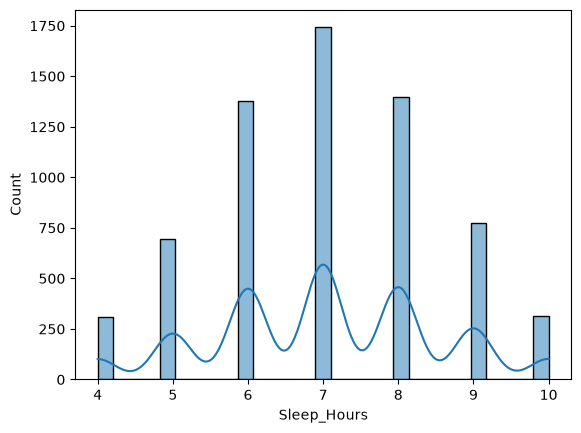

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data["Sleep_Hours"], kde=True)
plt.show()

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

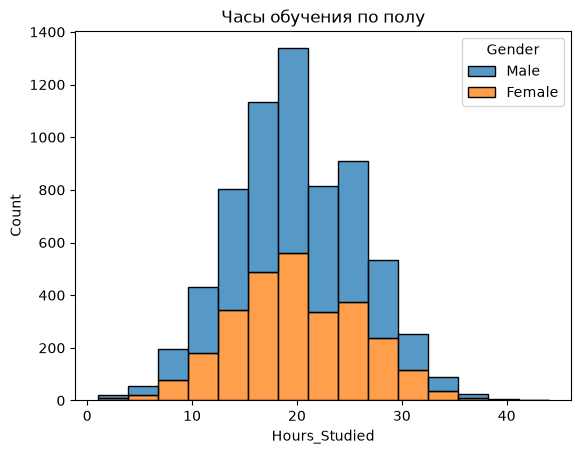

In [30]:
sns.histplot(data=data, x="Hours_Studied", hue="Gender", multiple="stack", bins=15)
plt.title("Часы обучения по полу")
plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

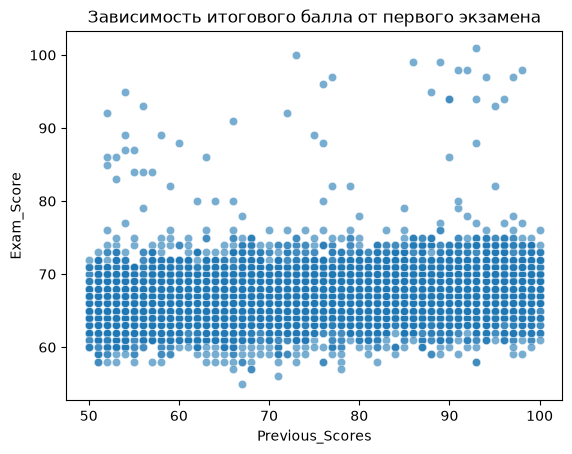

In [31]:
sns.scatterplot(data=data, x="Previous_Scores", y="Exam_Score", alpha=0.6)
plt.title("Зависимость итогового балла от первого экзамена")
plt.show()

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

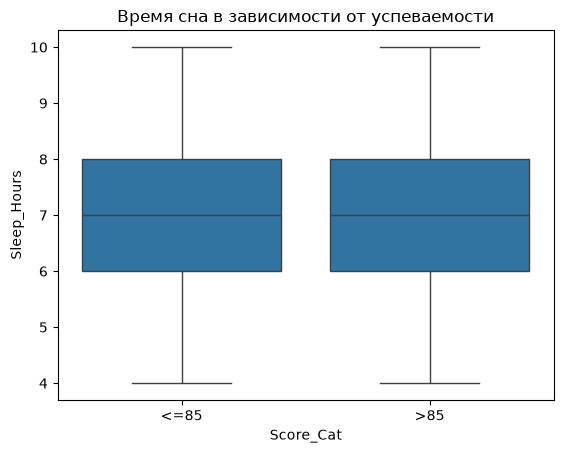

In [32]:
data["Score_Cat"] = data["Exam_Score"].apply(lambda x: ">85" if x > 85 else "<=85")
sns.boxplot(data=data, x="Score_Cat", y="Sleep_Hours")
plt.title("Время сна в зависимости от успеваемости")
plt.show()

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

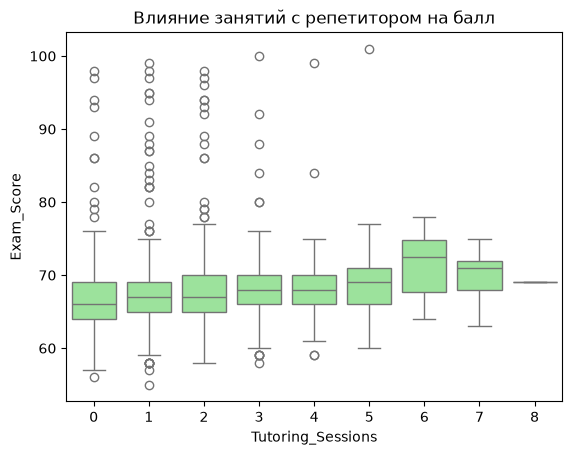

In [33]:
sns.boxplot(data=data, x="Tutoring_Sessions", y="Exam_Score", color="lightgreen")
plt.title("Влияние занятий с репетитором на балл")
plt.show()

6. Как физическая активность влияет на успеваемость?

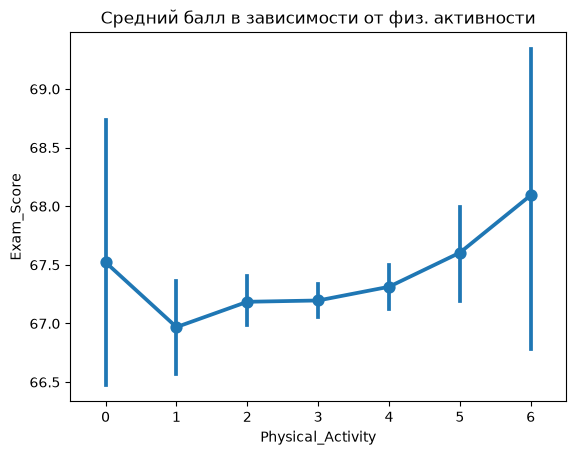

In [34]:
sns.pointplot(data=data, x="Physical_Activity", y="Exam_Score")
plt.title("Средний балл в зависимости от физ. активности")
plt.show()

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

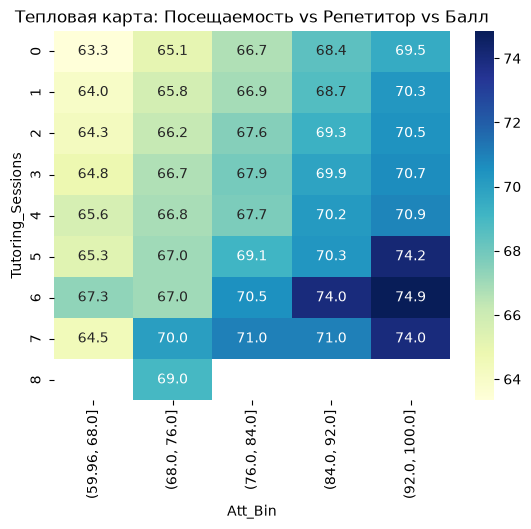

In [35]:
data["Att_Bin"] = pd.cut(data["Attendance"], bins=5)
pivot = data.pivot_table(index="Tutoring_Sessions", columns="Att_Bin", values="Exam_Score", aggfunc="mean")
sns.heatmap(pivot, annot=True, cmap="YlGnBu", fmt=".1f")
plt.title("Тепловая карта: Посещаемость vs Репетитор vs Балл")
plt.show()